# Phase 3: demand-weather regressions

Exploratory OLS regressions of daily NEM regional electricity demand on heating
and cooling degree days (HDD/CDD). This checks whether the demand response to
weather is strong and stable enough to justify weather-year-specific annual and
seasonal energy for AEMO OPSO reference-year traces. Not a forecast; OLS only.

Reads `data/processed/daily_model_dataset.parquet` (Phase 2 output) and
`inputs/station_mapping.csv` (HDD/CDD thresholds for the diagnostic plots) only.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols

BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / 'data' / 'processed' / 'daily_model_dataset.parquet'
STATION_MAPPING_PATH = BASE_DIR / 'inputs' / 'station_mapping.csv'
OUTPUTS_DIR = BASE_DIR / 'outputs'
FIGURES_DIR = OUTPUTS_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Akaysha Energy brand colours (Nov 2024 brand guidelines, docs/examples/monthly_update.ipynb).
# Inter is the documented fallback font but the file is not available in this
# environment, so the matplotlib default font is used instead.
AKAYSHA_PINE = '#003723'
AKAYSHA_MOSS = '#00743C'
AKAYSHA_JADE = '#007864'
AKAYSHA_SPRING = '#46C86E'
AKAYSHA_LIME = '#C7F77A'
AKAYSHA_AMARANTH = '#E75751'
AKAYSHA_AMBER = '#F69B4E'
AKAYSHA_AQUA = '#99D9E7'
AKAYSHA_AZURE = '#509EE3'

plt.rcParams.update({
    'axes.facecolor': 'white',
    'figure.facecolor': 'white',
    'savefig.facecolor': 'white',
    'axes.edgecolor': '#444444',
    'axes.labelcolor': 'black',
    'text.color': 'black',
    'axes.titlecolor': 'black',
    'grid.color': '#DDDDDD',
    'grid.linewidth': 0.6,
    'axes.grid': True,
    'axes.axisbelow': True,
    'font.size': 10,
})

REGIONS = ['NSW1', 'QLD1', 'SA1', 'TAS1', 'VIC1']
# Fixed categorical colour per region, never re-cycled. Chosen for mutual
# distinctness (not five shades of green).
REGION_COLOR = {
    'NSW1': AKAYSHA_PINE,
    'QLD1': AKAYSHA_AMBER,
    'SA1': AKAYSHA_AZURE,
    'TAS1': AKAYSHA_AMARANTH,
    'VIC1': AKAYSHA_SPRING,
}
DEP_VAR_COLOR = {
    'underlying_gwh': AKAYSHA_PINE,
    'oper_gwh': AKAYSHA_AMBER,
    'total_gwh': AKAYSHA_JADE,
    'total_pv_gwh': AKAYSHA_AQUA,
}

In [2]:
df = pd.read_parquet(DATA_PATH)
df['date'] = pd.to_datetime(df['date'])
df['sin_doy'] = np.sin(2 * np.pi * df['doy'] / 365.25)
df['cos_doy'] = np.cos(2 * np.pi * df['doy'] / 365.25)

station_mapping = pd.read_csv(STATION_MAPPING_PATH)
THRESHOLDS = station_mapping.groupby('region')[['hdd_threshold', 'cdd_threshold']].first()

assert set(df['region'].unique()) == set(REGIONS), 'unexpected region set'
print(df.shape, df['date'].min().date(), '->', df['date'].max().date())
THRESHOLDS

(46870, 40) 2001-01-01 -> 2026-08-31


,hdd_threshold,cdd_threshold
region,,
NSW1,17.0,21.5
QLD1,17.0,22.0
SA1,16.5,22.0
TAS1,16.0,20.0
VIC1,16.5,21.0


## Fit helper

`select_sample` applies the common-sample rule for a given (region, dep var,
window, extra quality columns): the dep-var quality flag, `ok_temp` and
`ok_temp_lag` must all be true, plus any `extra_ok_cols` (used for run E's
`ok_temp_mm` and run F's cross-checks against the other dep var's flag). It also
computes `trend` relative to the window start, per §6.

`fit` runs `select_sample`, then OLS with HAC (Newey-West, maxlags=7) standard
errors, and returns a tidy row plus the fitted `statsmodels` result (the result
is kept so later cells can build diagnostic and coefficient figures without
refitting).

Long-run (M4) HDD/CDD coefficients are `HDD + HDD_lag1` and `CDD + CDD_lag1`,
with SE/p/CI from `res.t_test(...)`, per §6.

In [3]:
DEP_OK = {
    'underlying_gwh': 'ok_underlying',
    'oper_gwh': 'ok_oper',
    'total_gwh': 'ok_total',
    'total_pv_gwh': 'ok_total_pv',
}

M1 = 'y ~ HDD + CDD'
M2 = 'y ~ HDD + CDD + C(dow) + C(month) + holiday + xmas_period + trend'
M3 = 'y ~ HDD + CDD + C(dow) + holiday + xmas_period + trend + sin_doy + cos_doy'
M4 = 'y ~ HDD + CDD + HDD_lag1 + CDD_lag1 + C(dow) + C(month) + holiday + xmas_period + trend'
ME = 'y ~ HDD_mm + CDD_mm + C(dow) + C(month) + holiday + xmas_period + trend'  # run E only


def select_sample(region_df, window, dep_var, extra_ok_cols=None):
    'Common-sample rows for one region, one dep var, one window (inclusive).'
    region_vals = region_df['region'].unique()
    if len(region_vals) != 1:
        raise ValueError('select_sample expects a single-region df')
    start, end = pd.Timestamp(window[0]), pd.Timestamp(window[1])
    d = region_df[(region_df['date'] >= start) & (region_df['date'] <= end)].copy()
    mask = d[DEP_OK[dep_var]] & d['ok_temp'] & d['ok_temp_lag']
    for col in (extra_ok_cols or []):
        mask = mask & d[col]
    d = d[mask].copy()
    d['trend'] = (d['date'] - start).dt.days / 365.25
    return d


_SLOTS = [
    ('HDD', ['HDD', 'HDD_mm']),
    ('CDD', ['CDD', 'CDD_mm']),
    ('HDD_lag1', ['HDD_lag1', 'HDD_mm_lag1']),
    ('CDD_lag1', ['CDD_lag1', 'CDD_mm_lag1']),
]
_LR_SLOTS = [
    ('HDD_LR', ['HDD', 'HDD_mm'], ['HDD_lag1', 'HDD_mm_lag1']),
    ('CDD_LR', ['CDD', 'CDD_mm'], ['CDD_lag1', 'CDD_mm_lag1']),
]


def fit(region_df, formula, window, dep_var, extra_ok_cols=None):
    'Fit one OLS model for one region. Returns (tidy row dict, fitted result).'
    d = select_sample(region_df, window, dep_var, extra_ok_cols=extra_ok_cols)
    if d.empty:
        raise RuntimeError(f'empty common sample for {dep_var}, window {window}')
    region = d['region'].iloc[0]

    assert formula.startswith('y ~'), formula
    formula_full = dep_var + formula[1:]
    res = ols(formula_full, data=d).fit(cov_type='HAC', cov_kwds={'maxlags': 7})

    start = pd.Timestamp(window[0])
    row = {
        'region': region, 'dep_var': dep_var, 'n': len(d),
        'window_start': pd.Timestamp(window[0]).date(),
        'window_end': pd.Timestamp(window[1]).date(),
        'r2': res.rsquared, 'adj_r2': res.rsquared_adj,
    }

    for slot, candidates in _SLOTS:
        term = next((c for c in candidates if c in res.params.index), None)
        if term is None:
            row[f'b_{slot}'] = row[f'se_{slot}'] = row[f'p_{slot}'] = np.nan
            row[f'ci_lo_{slot}'] = row[f'ci_hi_{slot}'] = np.nan
        else:
            ci = res.conf_int().loc[term]
            row[f'b_{slot}'] = res.params[term]
            row[f'se_{slot}'] = res.bse[term]
            row[f'p_{slot}'] = res.pvalues[term]
            row[f'ci_lo_{slot}'], row[f'ci_hi_{slot}'] = ci[0], ci[1]

    for slot, cur_cands, lag_cands in _LR_SLOTS:
        cur = next((c for c in cur_cands if c in res.params.index), None)
        lag = next((c for c in lag_cands if c in res.params.index), None)
        if cur is not None and lag is not None:
            tt = res.t_test(f'{cur} + {lag} = 0')
            row[f'b_{slot}'] = float(np.asarray(tt.effect).ravel()[0])
            row[f'se_{slot}'] = float(np.asarray(tt.sd).ravel()[0])
            row[f'p_{slot}'] = float(np.asarray(tt.pvalue).ravel()[0])
            ci = np.asarray(tt.conf_int()).ravel()
            row[f'ci_lo_{slot}'], row[f'ci_hi_{slot}'] = ci[0], ci[1]
        else:
            row[f'b_{slot}'] = row[f'se_{slot}'] = row[f'p_{slot}'] = np.nan
            row[f'ci_lo_{slot}'] = row[f'ci_hi_{slot}'] = np.nan

    return row, res

## Run matrix (§6)

Windows and helper to run and record a fit, tagged with `run_id` and `model`.
`extra_ok_cols` used per row is kept alongside each result (in memory only, not
written to CSV) so the acceptance cell can recompute `n` independently.

In [4]:
PRIMARY = ('2022-09-01', '2026-08-31')   # run A: primary window
ROBUST = ('2021-01-01', '2026-08-31')    # run B
LONG_WINDOW = ('2010-01-01', '2026-08-31')  # run C
F_WINDOW = ('2021-01-01', '2026-08-31')  # run F (same span as ROBUST)


def rolling_windows():
    'Windows start 1 Jan, end 31 Dec of end_year, for end_year 2013..2025.'
    return [
        ((dt.date(end_year - 3, 1, 1), dt.date(end_year, 12, 31)), end_year)
        for end_year in range(2013, 2026)
    ]


results = []          # list of tidy row dicts -> outputs/regression_results.csv
saved_fits = {}        # (region) -> res, run A / M2 / underlying_gwh / primary, for diag plots


def run_fit(run_id, model_label, formula, window, dep_var, region, extra_ok_cols=None):
    region_df = df[df['region'] == region]
    row, res = fit(region_df, formula, window, dep_var, extra_ok_cols=extra_ok_cols)
    row['run_id'] = run_id
    row['model'] = model_label
    results.append(row)
    return row, res


MODELS = [('M1', M1), ('M2', M2), ('M3', M3), ('M4', M4)]

### Run A -- primary window, M1-M4, underlying_gwh and oper_gwh

In [5]:
for region in REGIONS:
    for dep_var in ['underlying_gwh', 'oper_gwh']:
        for model_label, formula in MODELS:
            row, res = run_fit('A', model_label, formula, PRIMARY, dep_var, region)
            if model_label == 'M2' and dep_var == 'underlying_gwh':
                saved_fits[region] = res

print('Run A rows:', sum(1 for r in results if r['run_id'] == 'A'))

Run A rows: 40


### Run B -- robustness window (2021-01-01 -> 2026-08-31), M1-M4

In [6]:
for region in REGIONS:
    for dep_var in ['underlying_gwh', 'oper_gwh']:
        for model_label, formula in MODELS:
            run_fit('B', model_label, formula, ROBUST, dep_var, region)

print('Run B rows:', sum(1 for r in results if r['run_id'] == 'B'))

Run B rows: 40


### Run C -- long history (2010-01-01 -> 2026-08-31), M2, total_gwh

In [7]:
for region in REGIONS:
    run_fit('C', 'M2', M2, LONG_WINDOW, 'total_gwh', region)

print('Run C rows:', sum(1 for r in results if r['run_id'] == 'C'))

Run C rows: 5


### Run D -- rolling 4-year windows, M2

`total_gwh`: the 13 rolling windows ending 31 Dec 2013..2025, plus the primary
window (2022-09-01 -> 2026-08-31). `total_pv_gwh`: the same rolling windows,
restricted to those starting on or after 2019-01-01 (end year >= 2022).

In [8]:
rolling = rolling_windows()

for region in REGIONS:
    for window, end_year in rolling:
        run_fit('D', 'M2', M2, window, 'total_gwh', region)
    run_fit('D', 'M2', M2, PRIMARY, 'total_gwh', region)  # extra window, total_gwh only

    for window, end_year in rolling:
        if window[0] >= dt.date(2019, 1, 1):
            run_fit('D', 'M2', M2, window, 'total_pv_gwh', region)

print('Run D rows:', sum(1 for r in results if r['run_id'] == 'D'))

Run D rows: 90


### Run E -- max/min temperature sensitivity, primary window, M2, underlying_gwh

Uses `HDD_mm`/`CDD_mm` in place of `HDD`/`CDD`; the common sample is run A's
underlying_gwh common sample further restricted to `ok_temp_mm`. The `fit`
helper stores the coefficients in the usual `b_HDD`/`b_CDD` columns; `run_id`
'E' identifies them as max/min-based.

In [9]:
for region in REGIONS:
    run_fit('E', 'M2', ME, PRIMARY, 'underlying_gwh', region, extra_ok_cols=['ok_temp_mm'])

print('Run E rows:', sum(1 for r in results if r['run_id'] == 'E'))

Run E rows: 5


### Run F -- total vs operational demand overlap, 2021-01-01 -> 2026-08-31

M2 fit for `total_gwh` and for `oper_gwh` on a common sample where `ok_total`,
`ok_oper`, `ok_temp` and `ok_temp_lag` all hold, so the two coefficients are on
the same days. `overlap_check.csv` adds the daily correlation and ratio stats
on that same sample.

In [10]:
overlap_rows = []

for region in REGIONS:
    row_total, _ = run_fit('F', 'M2', M2, F_WINDOW, 'total_gwh', region, extra_ok_cols=['ok_oper'])
    row_oper, _ = run_fit('F', 'M2', M2, F_WINDOW, 'oper_gwh', region, extra_ok_cols=['ok_total'])

    d_sample = select_sample(df[df['region'] == region], F_WINDOW, 'total_gwh', extra_ok_cols=['ok_oper'])
    ratio = d_sample['total_gwh'] / d_sample['oper_gwh']
    overlap_rows.append({
        'region': region,
        'n': len(d_sample),
        'corr': d_sample['total_gwh'].corr(d_sample['oper_gwh']),
        'mean_ratio': ratio.mean(),
        'ratio_std': ratio.std(),
        'b_HDD_total': row_total['b_HDD'], 'b_HDD_oper': row_oper['b_HDD'],
        'b_CDD_total': row_total['b_CDD'], 'b_CDD_oper': row_oper['b_CDD'],
    })

overlap_check = pd.DataFrame(overlap_rows)
overlap_check.to_csv(OUTPUTS_DIR / 'overlap_check.csv', index=False)
overlap_check

,region,n,corr,mean_ratio,ratio_std,b_HDD_total,b_HDD_oper,b_CDD_total,b_CDD_oper
0,NSW1,2046,0.998532,0.988659,0.006194,3.716482,3.598434,6.858358,6.897672
1,QLD1,2036,0.998950,0.995128,0.004058,0.738103,0.743565,5.109125,5.097023
2,SA1,2040,0.982740,0.979788,0.034035,0.692468,0.644129,1.768882,1.774643
3,TAS1,2036,0.954742,0.960133,0.030071,0.351807,0.313776,0.044516,0.188378
4,VIC1,2047,0.990743,0.959937,0.019967,2.436514,2.053543,5.930484,5.885855


## Save `regression_results.csv`

In [11]:
results_df = pd.DataFrame(results)
ordered_cols = [
    'run_id', 'region', 'model', 'dep_var', 'window_start', 'window_end', 'n',
    'b_HDD', 'se_HDD', 'p_HDD', 'ci_lo_HDD', 'ci_hi_HDD',
    'b_CDD', 'se_CDD', 'p_CDD', 'ci_lo_CDD', 'ci_hi_CDD',
    'b_HDD_lag1', 'se_HDD_lag1', 'p_HDD_lag1', 'ci_lo_HDD_lag1', 'ci_hi_HDD_lag1',
    'b_CDD_lag1', 'se_CDD_lag1', 'p_CDD_lag1', 'ci_lo_CDD_lag1', 'ci_hi_CDD_lag1',
    'b_HDD_LR', 'se_HDD_LR', 'p_HDD_LR', 'ci_lo_HDD_LR', 'ci_hi_HDD_LR',
    'b_CDD_LR', 'se_CDD_LR', 'p_CDD_LR', 'ci_lo_CDD_LR', 'ci_hi_CDD_LR',
    'r2', 'adj_r2',
]
results_df = results_df[ordered_cols]
results_df.to_csv(OUTPUTS_DIR / 'regression_results.csv', index=False)
print(results_df.shape)
results_df.head()

(190, 39)


,run_id,region,model,dep_var,window_start,window_end,n,b_HDD,se_HDD,p_HDD,...,p_HDD_LR,ci_lo_HDD_LR,ci_hi_HDD_LR,b_CDD_LR,se_CDD_LR,p_CDD_LR,ci_lo_CDD_LR,ci_hi_CDD_LR,r2,adj_r2
0,A,NSW1,M1,underlying_gwh,2022-09-01,2026-08-31,1434,5.678671,0.203147,5.966843e-172,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.661544,0.661071
1,A,NSW1,M2,underlying_gwh,2022-09-01,2026-08-31,1434,4.088610,0.193054,1.504287e-99,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.899129,0.897556
2,A,NSW1,M3,underlying_gwh,2022-09-01,2026-08-31,1434,5.568560,0.187389,4.695518e-194,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.858648,0.857354
3,A,NSW1,M4,underlying_gwh,2022-09-01,2026-08-31,1434,3.090009,0.153094,1.359563e-90,...,9.754898e-113,4.165035,4.95743,8.578502,0.222346,0.0,8.142712,9.014292,0.906696,0.905107
4,A,NSW1,M1,oper_gwh,2022-09-01,2026-08-31,1438,7.035675,0.228849,1.480214e-207,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.590837,0.590267


## Acceptance cell

Every expected (run_id, region, model, dep_var, window) combination from the
run matrix must be present, and `n` must equal an independently recomputed
common-sample count (via `select_sample`, called fresh with the same
arguments the run used).

In [12]:
expected = []
for region in REGIONS:
    for dep_var in ['underlying_gwh', 'oper_gwh']:
        for model_label, _ in MODELS:
            expected.append(('A', region, model_label, dep_var, PRIMARY, None))
            expected.append(('B', region, model_label, dep_var, ROBUST, None))
for region in REGIONS:
    expected.append(('C', region, 'M2', 'total_gwh', LONG_WINDOW, None))
for region in REGIONS:
    for window, end_year in rolling:
        expected.append(('D', region, 'M2', 'total_gwh', window, None))
    expected.append(('D', region, 'M2', 'total_gwh', PRIMARY, None))
    for window, end_year in rolling:
        if window[0] >= dt.date(2019, 1, 1):
            expected.append(('D', region, 'M2', 'total_pv_gwh', window, None))
for region in REGIONS:
    expected.append(('E', region, 'M2', 'underlying_gwh', PRIMARY, ['ok_temp_mm']))
for region in REGIONS:
    expected.append(('F', region, 'M2', 'total_gwh', F_WINDOW, ['ok_oper']))
    expected.append(('F', region, 'M2', 'oper_gwh', F_WINDOW, ['ok_total']))

assert len(expected) == len(results_df), (len(expected), len(results_df))

checked = 0
for run_id, region, model_label, dep_var, window, extra_ok_cols in expected:
    ws, we = pd.Timestamp(window[0]).date(), pd.Timestamp(window[1]).date()
    match = results_df[
        (results_df['run_id'] == run_id) & (results_df['region'] == region)
        & (results_df['model'] == model_label) & (results_df['dep_var'] == dep_var)
        & (results_df['window_start'] == ws) & (results_df['window_end'] == we)
    ]
    assert len(match) == 1, f'missing/duplicate row for {(run_id, region, model_label, dep_var, window)}'
    expected_n = len(select_sample(df[df['region'] == region], window, dep_var, extra_ok_cols=extra_ok_cols))
    actual_n = match.iloc[0]['n']
    assert expected_n == actual_n, (run_id, region, model_label, dep_var, window, expected_n, actual_n)
    checked += 1

print(f'Acceptance OK: {checked} rows present, all n recomputed and matched.')

Acceptance OK: 190 rows present, all n recomputed and matched.


## `coefficient_flags.csv`

One row per (region, dep_var) for `dep_var` in `{underlying_gwh, oper_gwh}`,
from run A. `cdd_underlying_vs_oper_ratio`, `hdd_rolling_range` and
`cdd_rolling_range` depend only on region, so the same value is repeated on
both dep-var rows for that region.

`hdd_rolling_range`/`cdd_rolling_range` use run D's `total_gwh` beta over the 13
rolling windows ending 2013..2025 (the extra 2022-09 -> 2026-08 window is
excluded, to match the calendar-year rolling definition). If the min beta over
those windows is <= 0, the max/min ratio is meaningless, so the value is set to
NaN (noted in the handover, not substituted).

In [13]:
flags = []
extra_start = pd.Timestamp(PRIMARY[0]).date()

for region in REGIONS:
    a = {}
    for model_label, _ in MODELS:
        for dep_var in ['underlying_gwh', 'oper_gwh']:
            a[(model_label, dep_var)] = results_df[
                (results_df['run_id'] == 'A') & (results_df['region'] == region)
                & (results_df['model'] == model_label) & (results_df['dep_var'] == dep_var)
            ].iloc[0]

    cdd_underlying_vs_oper_ratio = a[('M2', 'underlying_gwh')]['b_CDD'] / a[('M2', 'oper_gwh')]['b_CDD']

    d_rows = results_df[
        (results_df['run_id'] == 'D') & (results_df['region'] == region)
        & (results_df['model'] == 'M2') & (results_df['dep_var'] == 'total_gwh')
        & (results_df['window_start'] != extra_start)
    ]
    assert len(d_rows) == 13, (region, len(d_rows))
    hdd_vals, cdd_vals = d_rows['b_HDD'], d_rows['b_CDD']
    hdd_rolling_range = (hdd_vals.max() / hdd_vals.min() - 1) if hdd_vals.min() > 0 else np.nan
    cdd_rolling_range = (cdd_vals.max() / cdd_vals.min() - 1) if cdd_vals.min() > 0 else np.nan

    for dep_var in ['underlying_gwh', 'oper_gwh']:
        m1, m2, m3, m4 = a[('M1', dep_var)], a[('M2', dep_var)], a[('M3', dep_var)], a[('M4', dep_var)]
        hdd_spread_vals = [m2['b_HDD'], m3['b_HDD'], m4['b_HDD_LR']]
        cdd_spread_vals = [m2['b_CDD'], m3['b_CDD'], m4['b_CDD_LR']]
        flags.append({
            'region': region, 'dep_var': dep_var,
            'hdd_sign_ok': bool(m2['b_HDD'] > 0),
            'cdd_sign_ok': bool(m2['b_CDD'] > 0),
            'hdd_sig': bool(m2['p_HDD'] < 0.05),
            'cdd_sig': bool(m2['p_CDD'] < 0.05),
            'hdd_spread_m2_m3_m4lr': max(hdd_spread_vals) / min(hdd_spread_vals) - 1,
            'cdd_spread_m2_m3_m4lr': max(cdd_spread_vals) / min(cdd_spread_vals) - 1,
            'hdd_m1_to_m2_pct': m2['b_HDD'] / m1['b_HDD'] - 1,
            'cdd_m1_to_m2_pct': m2['b_CDD'] / m1['b_CDD'] - 1,
            'cdd_underlying_vs_oper_ratio': cdd_underlying_vs_oper_ratio,
            'hdd_rolling_range': hdd_rolling_range,
            'cdd_rolling_range': cdd_rolling_range,
        })

coefficient_flags = pd.DataFrame(flags)
coefficient_flags.to_csv(OUTPUTS_DIR / 'coefficient_flags.csv', index=False)
coefficient_flags

,region,dep_var,hdd_sign_ok,cdd_sign_ok,hdd_sig,cdd_sig,hdd_spread_m2_m3_m4lr,cdd_spread_m2_m3_m4lr,hdd_m1_to_m2_pct,cdd_m1_to_m2_pct,cdd_underlying_vs_oper_ratio,hdd_rolling_range,cdd_rolling_range
0,NSW1,underlying_gwh,True,True,True,True,0.361969,0.089375,-0.280006,-0.100166,1.169775,0.404866,0.388202
1,NSW1,oper_gwh,True,True,True,True,0.473288,0.136096,-0.453527,-0.016752,1.169775,0.404866,0.388202
2,QLD1,underlying_gwh,True,True,True,True,0.252083,0.046555,0.124029,-0.162265,1.184090,0.962713,0.465666
3,QLD1,oper_gwh,True,True,True,True,0.925740,0.141024,-0.526264,-0.121447,1.184090,0.962713,0.465666
4,SA1,underlying_gwh,True,True,True,True,0.477956,0.085861,-0.290911,-0.094360,0.988629,0.289615,0.106264
5,SA1,oper_gwh,True,True,True,True,0.445302,0.134396,-0.625682,0.054303,0.988629,0.289615,0.106264
6,TAS1,underlying_gwh,True,True,True,True,0.072833,0.463278,-0.388870,-0.327324,0.778044,0.200906,132.910334
7,TAS1,oper_gwh,True,True,True,True,0.080247,0.312586,-0.500283,-0.184275,0.778044,0.200906,132.910334
8,VIC1,underlying_gwh,True,True,True,True,0.237737,0.111658,-0.366218,0.001582,1.013370,0.605032,0.477531
9,VIC1,oper_gwh,True,True,True,True,0.267804,0.135967,-0.574052,0.115179,1.013370,0.605032,0.477531


## Figures

### `diag_{region}.png` -- M2 / underlying_gwh / primary window, per region

Four panels: daily energy vs mean temperature (with vertical lines at the
region's HDD/CDD thresholds), actual vs fitted over time, residuals over time,
and residuals vs fitted.

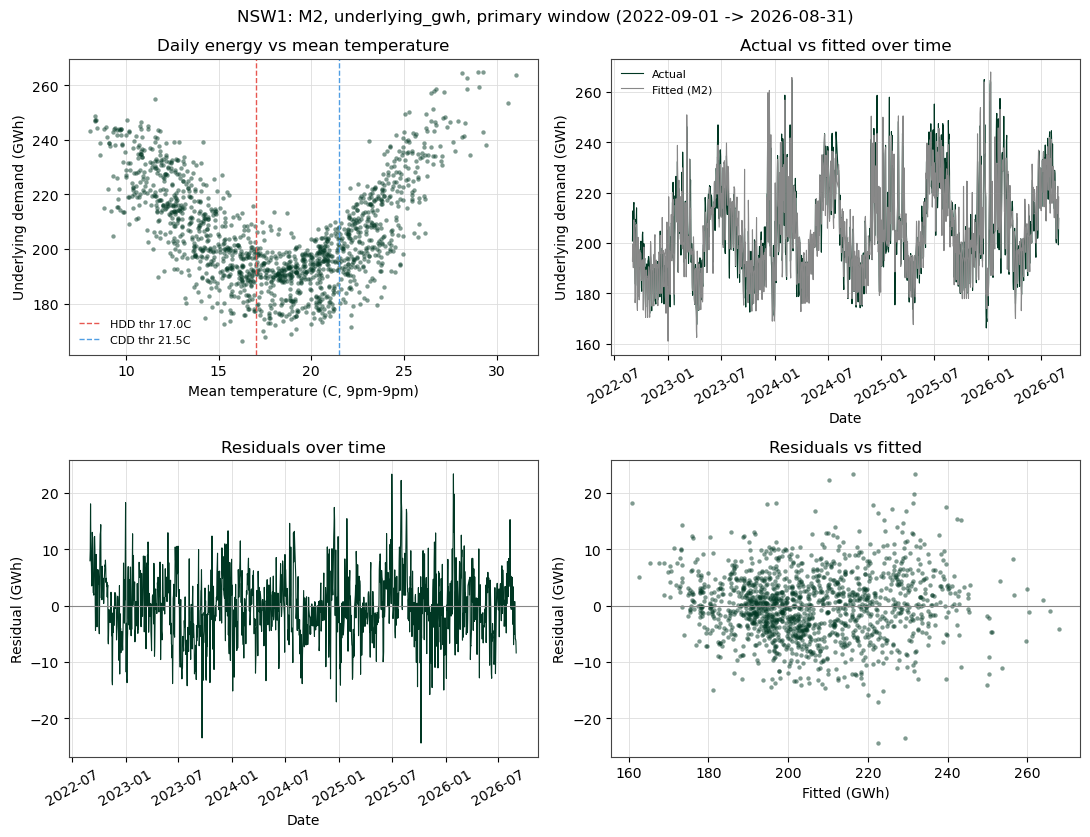

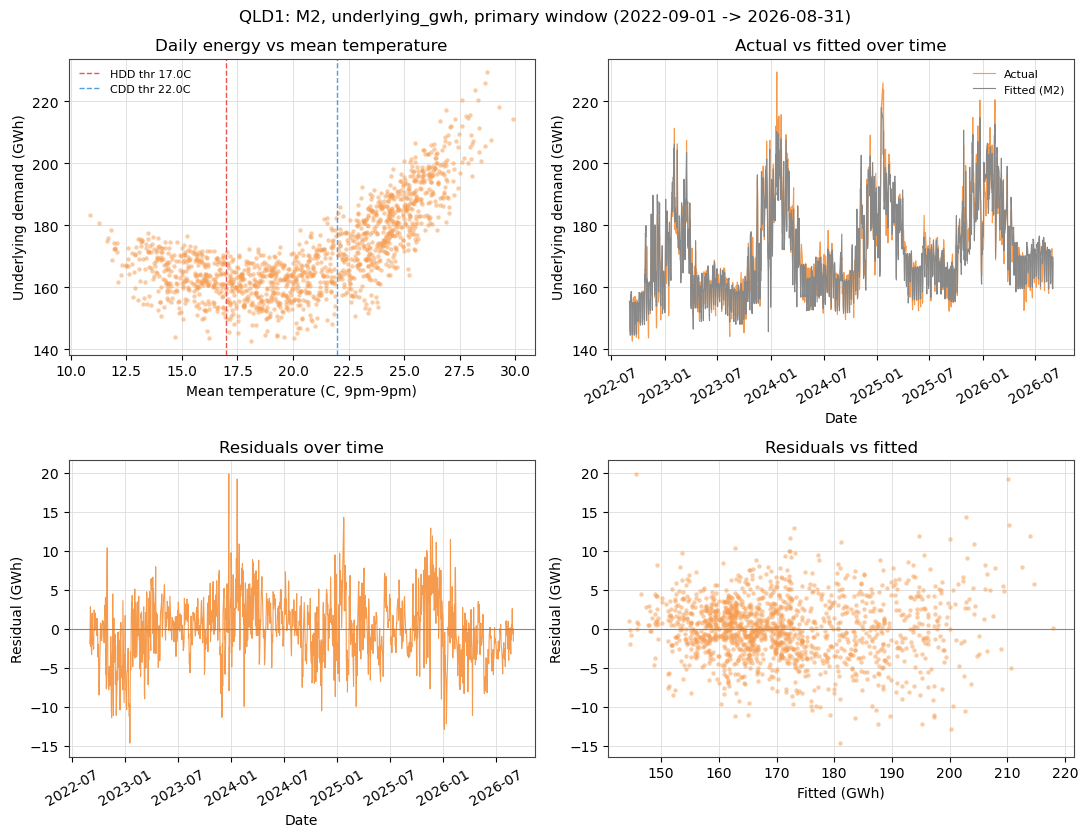

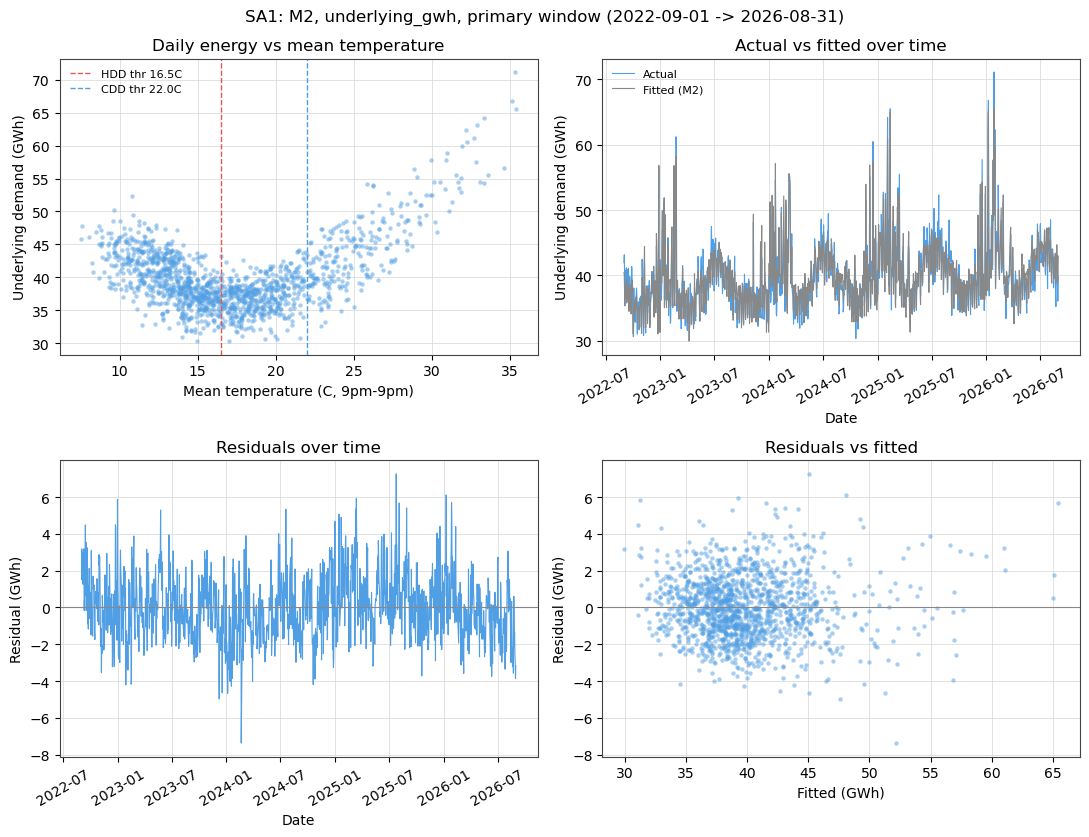

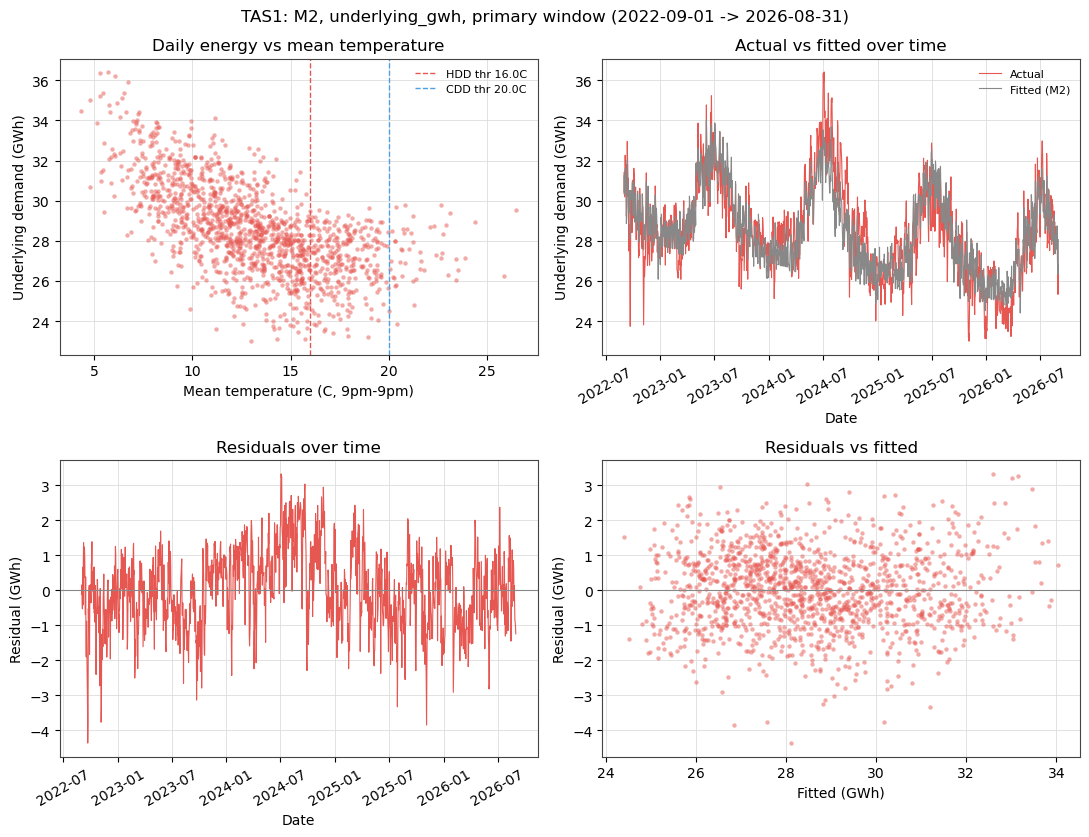

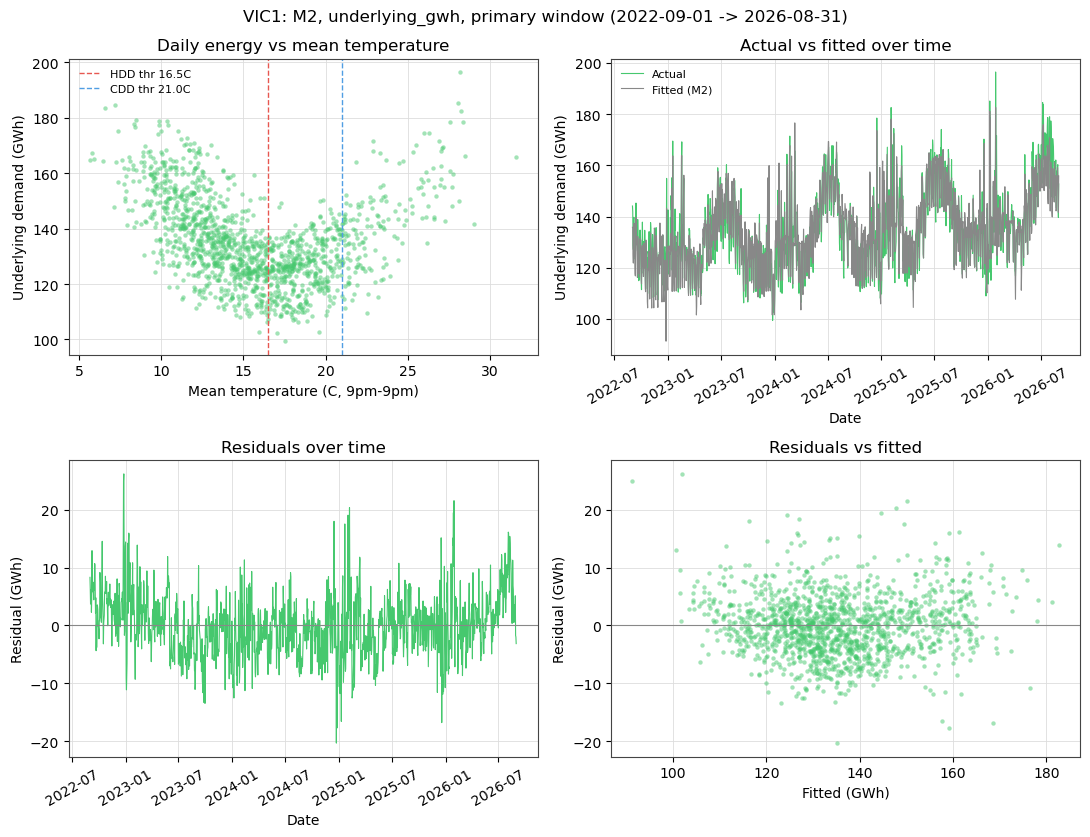

In [14]:
for region in REGIONS:
    res = saved_fits[region]
    d = select_sample(df[df['region'] == region], PRIMARY, 'underlying_gwh')
    thr = THRESHOLDS.loc[region]

    fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
    color = REGION_COLOR[region]

    ax = axes[0, 0]
    ax.scatter(d['mean_temp'], d['underlying_gwh'], s=10, color=color, alpha=0.5, linewidths=0)
    ax.axvline(thr['hdd_threshold'], color=AKAYSHA_AMARANTH, linestyle='--', linewidth=1, label=f"HDD thr {thr['hdd_threshold']:.1f}C")
    ax.axvline(thr['cdd_threshold'], color=AKAYSHA_AZURE, linestyle='--', linewidth=1, label=f"CDD thr {thr['cdd_threshold']:.1f}C")
    ax.set_xlabel('Mean temperature (C, 9pm-9pm)')
    ax.set_ylabel('Underlying demand (GWh)')
    ax.set_title('Daily energy vs mean temperature')
    ax.legend(frameon=False, fontsize=8)

    ax = axes[0, 1]
    ax.plot(d['date'], d['underlying_gwh'], color=color, linewidth=0.8, label='Actual')
    ax.plot(d['date'], res.fittedvalues, color='#888888', linewidth=0.8, label='Fitted (M2)')
    ax.set_xlabel('Date')
    ax.set_ylabel('Underlying demand (GWh)')
    ax.set_title('Actual vs fitted over time')
    ax.legend(frameon=False, fontsize=8)
    ax.tick_params(axis='x', rotation=30)

    ax = axes[1, 0]
    ax.plot(d['date'], res.resid, color=color, linewidth=0.8)
    ax.axhline(0, color='#888888', linewidth=0.8)
    ax.set_xlabel('Date')
    ax.set_ylabel('Residual (GWh)')
    ax.set_title('Residuals over time')
    ax.tick_params(axis='x', rotation=30)

    ax = axes[1, 1]
    ax.scatter(res.fittedvalues, res.resid, s=10, color=color, alpha=0.5, linewidths=0)
    ax.axhline(0, color='#888888', linewidth=0.8)
    ax.set_xlabel('Fitted (GWh)')
    ax.set_ylabel('Residual (GWh)')
    ax.set_title('Residuals vs fitted')

    fig.suptitle(f'{region}: M2, underlying_gwh, primary window (2022-09-01 -> 2026-08-31)')
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f'diag_{region}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

### `coef_comparison.png` -- beta_HDD, beta_CDD +/- 95% CI, M1-M4(LR) x dep_var x window (A, B, E), by region

For M4 the long-run estimate (`b_HDD_LR`/`b_CDD_LR`) is shown, labeled "M4 LR".
Run E (max/min temperature sensitivity) contributes one extra point per region,
for `underlying_gwh` / M2 only, labeled "M2 (mm)".

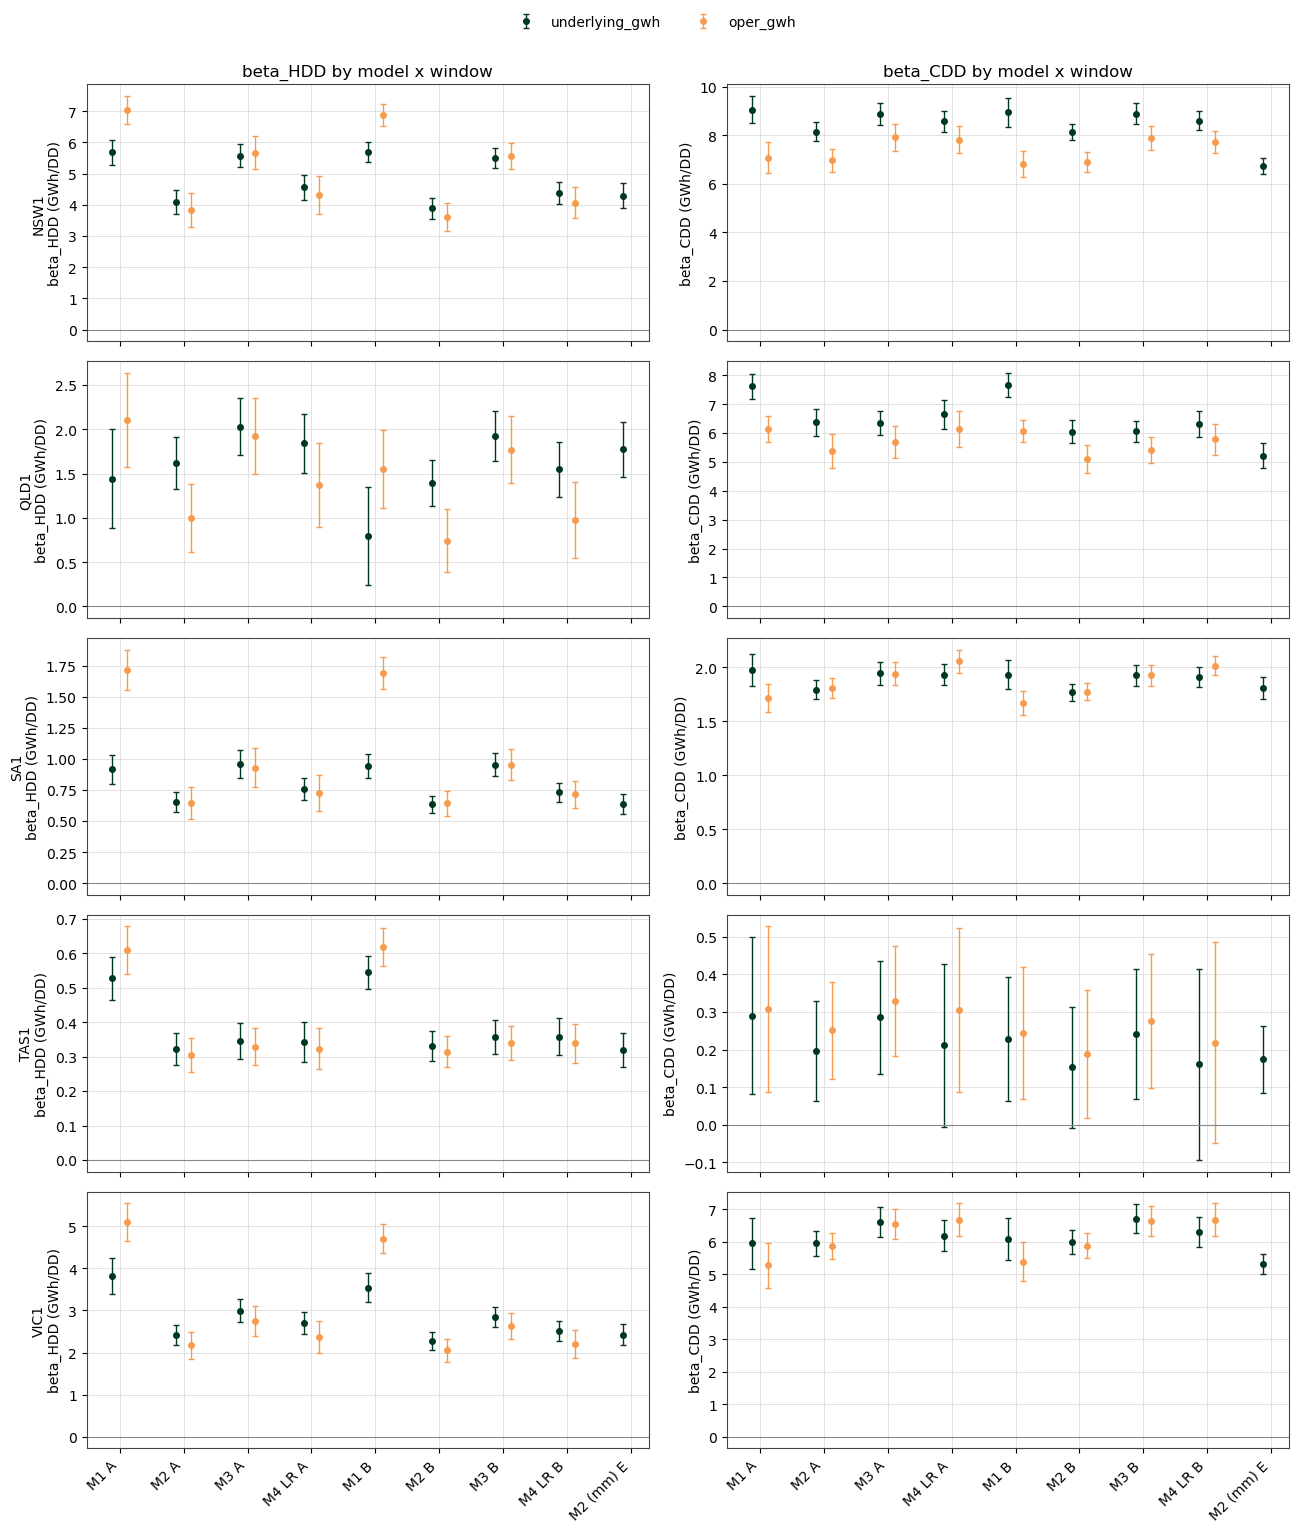

In [15]:
combo_rows = []

for run_id, window_label in [('A', 'A'), ('B', 'B')]:
    for dep_var in ['underlying_gwh', 'oper_gwh']:
        for model_label, _ in MODELS:
            for region in REGIONS:
                r = results_df[
                    (results_df['run_id'] == run_id) & (results_df['region'] == region)
                    & (results_df['model'] == model_label) & (results_df['dep_var'] == dep_var)
                ].iloc[0]
                if model_label == 'M4':
                    b_hdd, lo_hdd, hi_hdd = r['b_HDD_LR'], r['ci_lo_HDD_LR'], r['ci_hi_HDD_LR']
                    b_cdd, lo_cdd, hi_cdd = r['b_CDD_LR'], r['ci_lo_CDD_LR'], r['ci_hi_CDD_LR']
                    model_disp = 'M4 LR'
                else:
                    b_hdd, lo_hdd, hi_hdd = r['b_HDD'], r['ci_lo_HDD'], r['ci_hi_HDD']
                    b_cdd, lo_cdd, hi_cdd = r['b_CDD'], r['ci_lo_CDD'], r['ci_hi_CDD']
                    model_disp = model_label
                combo_rows.append({
                    'region': region, 'window': window_label, 'dep_var': dep_var, 'model': model_disp,
                    'b_HDD': b_hdd, 'lo_HDD': lo_hdd, 'hi_HDD': hi_hdd,
                    'b_CDD': b_cdd, 'lo_CDD': lo_cdd, 'hi_CDD': hi_cdd,
                })

for region in REGIONS:
    r = results_df[(results_df['run_id'] == 'E') & (results_df['region'] == region)].iloc[0]
    combo_rows.append({
        'region': region, 'window': 'E', 'dep_var': 'underlying_gwh', 'model': 'M2 (mm)',
        'b_HDD': r['b_HDD'], 'lo_HDD': r['ci_lo_HDD'], 'hi_HDD': r['ci_hi_HDD'],
        'b_CDD': r['b_CDD'], 'lo_CDD': r['ci_lo_CDD'], 'hi_CDD': r['ci_hi_CDD'],
    })

combo = pd.DataFrame(combo_rows)

x_categories = [
    f'{m} {w}' for w in ['A', 'B'] for m in ['M1', 'M2', 'M3', 'M4 LR']
] + ['M2 (mm) E']
x_pos = {cat: i for i, cat in enumerate(x_categories)}
combo['x_label'] = combo['model'] + ' ' + combo['window']
combo['x'] = combo['x_label'].map(x_pos)

dep_var_offset = {'underlying_gwh': -0.12, 'oper_gwh': 0.12}

fig, axes = plt.subplots(len(REGIONS), 2, figsize=(13, 3.1 * len(REGIONS)), sharex=True)

for i, region in enumerate(REGIONS):
    sub = combo[combo['region'] == region]
    for dep_var in ['underlying_gwh', 'oper_gwh']:
        s = sub[sub['dep_var'] == dep_var]
        offset = dep_var_offset[dep_var]
        for col, quantity in [(0, 'HDD'), (1, 'CDD')]:
            ax = axes[i, col]
            xv = s['x'] + offset
            yv = s[f'b_{quantity}']
            yerr = np.vstack([yv - s[f'lo_{quantity}'], s[f'hi_{quantity}'] - yv])
            ax.errorbar(
                xv, yv, yerr=yerr, fmt='o', markersize=4, capsize=2, linewidth=1,
                color=DEP_VAR_COLOR[dep_var], label=dep_var if i == 0 else None,
            )
    axes[i, 0].set_ylabel(f'{region}\nbeta_HDD (GWh/DD)')
    axes[i, 1].set_ylabel('beta_CDD (GWh/DD)')
    for col in (0, 1):
        axes[i, col].axhline(0, color='#888888', linewidth=0.8)

axes[0, 0].set_title('beta_HDD by model x window')
axes[0, 1].set_title('beta_CDD by model x window')
for col in (0, 1):
    axes[-1, col].set_xticks(range(len(x_categories)))
    axes[-1, col].set_xticklabels(x_categories, rotation=45, ha='right')
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.965))
fig.savefig(FIGURES_DIR / 'coef_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

### `rolling_betas.png` -- run D beta paths with CIs, by region

`total_gwh` M2 beta over the 13 rolling 4-year windows (x = window end year),
with 95% CI bands. `total_pv_gwh` M2 betas (2022-2025 end years only) are
overlaid as unshaded markers for comparison.

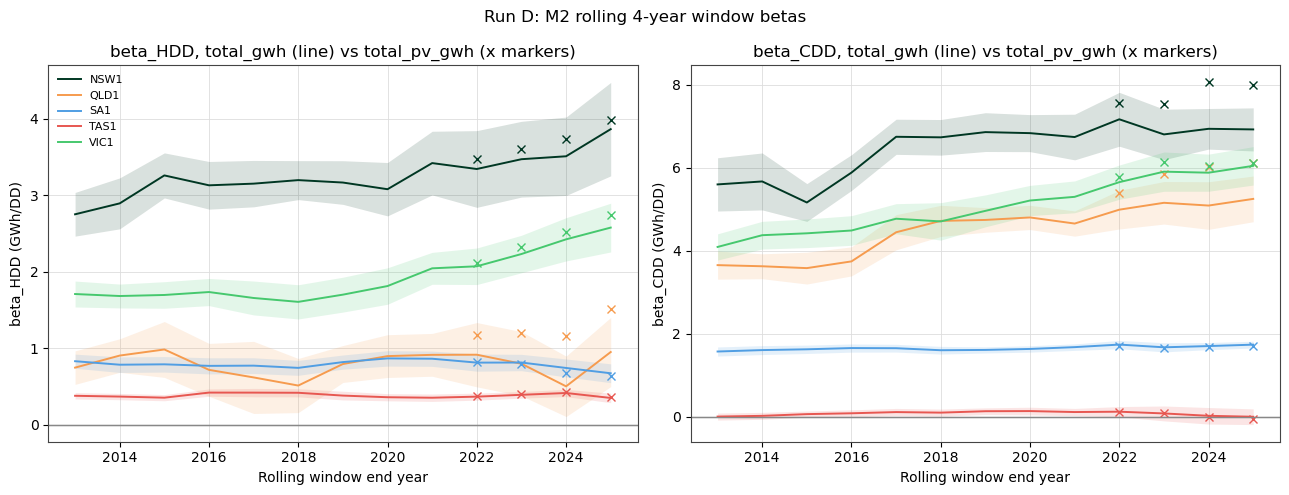

In [16]:
d_total = results_df[
    (results_df['run_id'] == 'D') & (results_df['dep_var'] == 'total_gwh')
    & (results_df['window_start'] != extra_start)
].copy()
d_total['end_year'] = pd.to_datetime(d_total['window_end']).dt.year

d_pv = results_df[(results_df['run_id'] == 'D') & (results_df['dep_var'] == 'total_pv_gwh')].copy()
d_pv['end_year'] = pd.to_datetime(d_pv['window_end']).dt.year

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)

for region in REGIONS:
    color = REGION_COLOR[region]
    s = d_total[d_total['region'] == region].sort_values('end_year')
    s_pv = d_pv[d_pv['region'] == region].sort_values('end_year')
    for col, quantity in [(0, 'HDD'), (1, 'CDD')]:
        ax = axes[col]
        ax.plot(s['end_year'], s[f'b_{quantity}'], color=color, linewidth=1.4, label=region)
        ax.fill_between(s['end_year'], s[f'ci_lo_{quantity}'], s[f'ci_hi_{quantity}'], color=color, alpha=0.15, linewidth=0)
        ax.plot(s_pv['end_year'], s_pv[f'b_{quantity}'], color=color, linewidth=0, marker='x', markersize=6)
        ax.axhline(0, color='#888888', linewidth=0.8)

axes[0].set_title('beta_HDD, total_gwh (line) vs total_pv_gwh (x markers)')
axes[1].set_title('beta_CDD, total_gwh (line) vs total_pv_gwh (x markers)')
axes[0].set_ylabel('beta_HDD (GWh/DD)')
axes[1].set_ylabel('beta_CDD (GWh/DD)')
for ax in axes:
    ax.set_xlabel('Rolling window end year')
axes[0].legend(frameon=False, fontsize=8, ncol=1)
fig.suptitle('Run D: M2 rolling 4-year window betas')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'rolling_betas.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

## Flag table output (run A, M2)

No conclusions or recommendations here -- that is Phase 5. This is a listing of
the coefficient-stability flags computed above.

In [17]:
coefficient_flags

,region,dep_var,hdd_sign_ok,cdd_sign_ok,hdd_sig,cdd_sig,hdd_spread_m2_m3_m4lr,cdd_spread_m2_m3_m4lr,hdd_m1_to_m2_pct,cdd_m1_to_m2_pct,cdd_underlying_vs_oper_ratio,hdd_rolling_range,cdd_rolling_range
0,NSW1,underlying_gwh,True,True,True,True,0.361969,0.089375,-0.280006,-0.100166,1.169775,0.404866,0.388202
1,NSW1,oper_gwh,True,True,True,True,0.473288,0.136096,-0.453527,-0.016752,1.169775,0.404866,0.388202
2,QLD1,underlying_gwh,True,True,True,True,0.252083,0.046555,0.124029,-0.162265,1.184090,0.962713,0.465666
3,QLD1,oper_gwh,True,True,True,True,0.925740,0.141024,-0.526264,-0.121447,1.184090,0.962713,0.465666
4,SA1,underlying_gwh,True,True,True,True,0.477956,0.085861,-0.290911,-0.094360,0.988629,0.289615,0.106264
5,SA1,oper_gwh,True,True,True,True,0.445302,0.134396,-0.625682,0.054303,0.988629,0.289615,0.106264
6,TAS1,underlying_gwh,True,True,True,True,0.072833,0.463278,-0.388870,-0.327324,0.778044,0.200906,132.910334
7,TAS1,oper_gwh,True,True,True,True,0.080247,0.312586,-0.500283,-0.184275,0.778044,0.200906,132.910334
8,VIC1,underlying_gwh,True,True,True,True,0.237737,0.111658,-0.366218,0.001582,1.013370,0.605032,0.477531
9,VIC1,oper_gwh,True,True,True,True,0.267804,0.135967,-0.574052,0.115179,1.013370,0.605032,0.477531


## Flag table (run A, M2; rolling ranges from run D total_gwh)

Listing only; no conclusions (Phase 5). Values copied from `outputs/coefficient_flags.csv`.

| region | dep_var | hdd_sign_ok | cdd_sign_ok | hdd_sig | cdd_sig | hdd_spread_m2_m3_m4lr | cdd_spread_m2_m3_m4lr | hdd_m1_to_m2_pct | cdd_m1_to_m2_pct | cdd_underlying_vs_oper_ratio | hdd_rolling_range | cdd_rolling_range |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| NSW1 | underlying_gwh | True | True | True | True | 0.362 | 0.089 | -0.280 | -0.100 | 1.170 | 0.405 | 0.388 |
| NSW1 | oper_gwh | True | True | True | True | 0.473 | 0.136 | -0.454 | -0.017 | 1.170 | 0.405 | 0.388 |
| QLD1 | underlying_gwh | True | True | True | True | 0.252 | 0.047 | 0.124 | -0.162 | 1.184 | 0.963 | 0.466 |
| QLD1 | oper_gwh | True | True | True | True | 0.926 | 0.141 | -0.526 | -0.121 | 1.184 | 0.963 | 0.466 |
| SA1 | underlying_gwh | True | True | True | True | 0.478 | 0.086 | -0.291 | -0.094 | 0.989 | 0.290 | 0.106 |
| SA1 | oper_gwh | True | True | True | True | 0.445 | 0.134 | -0.626 | 0.054 | 0.989 | 0.290 | 0.106 |
| TAS1 | underlying_gwh | True | True | True | True | 0.073 | 0.463 | -0.389 | -0.327 | 0.778 | 0.201 | 132.910 |
| TAS1 | oper_gwh | True | True | True | True | 0.080 | 0.313 | -0.500 | -0.184 | 0.778 | 0.201 | 132.910 |
| VIC1 | underlying_gwh | True | True | True | True | 0.238 | 0.112 | -0.366 | 0.002 | 1.013 | 0.605 | 0.478 |
| VIC1 | oper_gwh | True | True | True | True | 0.268 | 0.136 | -0.574 | 0.115 | 1.013 | 0.605 | 0.478 |